# Proyek Analisis Data: **Bike Sharing Dataset**
- **Nama:** Herlan Alan Suherman
- **Email:** herlanalansuherman06@gmail.com
- **ID Dicoding:** ds786b6y0730

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pengaruh kondisi cuaca (`weathersit`) terhadap rata-rata total penyewaan sepeda per jam berdasarkan data sepanjang tahun 2011 dan 2012?
- **Pertanyaan 2:** Bagaimana pola tren penyewaan sepeda harian berdasarkan jam jika dibandingkan antara hari kerja dan hari libur/akhir pekan selama periode 2011-2012?
- **Pertanyaan 3:** Musim manakah yang memberikan kontribusi volume penyewaan sepeda paling tinggi sepanjang tahun 2012?
- **Pertanyaan 4:** Bagaimana perbandingan kontribusi jumlah transaksi antara pengguna biasa  dan pengguna terdaftar  terhadap total penyewaan sepeda bulanan di sepanjang tahun 2011?
- **Pertanyaan 5:** Seberapa kuat korelasi antara suhu perasaan tubuh  dengan jumlah total transaksi penyewaan sepeda harian selama periode kuartal ke-3 (Juli-September) tahun 2012?

## Import Semua Packages/Library yang Digunakan

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

## Data Wrangling

### Gathering Data

#### Load df ...

In [4]:
df_day = pd.read_csv('day.csv')
df_day

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247,1867,2114
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644,2451,3095
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796


In [5]:
df_hour = pd.read_csv('hour.csv')
df_hour

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61


**Insight:**
- **Tentang Dataset:**
  Dataset ini merupakan data riwayat penyewaan sepeda (Bike Sharing) pada sistem *Capital Bikeshare* di Washington D.C., USA, selama tahun 2011-2012. Dataset tersedia dalam bentuk harian (`df_day`) dan per jam (`df_hour`).

- **Definisi Kolom-Kolom Utama:**
  * `instant`: Indeks catatan (ID unik).
  * `dteday`: Tanggal pencatatan.
  * `season`: Musim (1: Musim Semi, 2: Musim Panas, 3: Musim Gugur, 4: Musim Dingin).
  * `yr`: Tahun (0: 2011, 1: 2012).
  * `mnth`: Bulan (1 s.d. 12).
  * `hr`: Jam (0 s.d. 23 - hanya ada pada `df_hour`).
  * `holiday`: Status hari libur nasional (0: Tidak, 1: Ya).
  * `weekday`: Hari dalam seminggu (0 s.d. 6).
  * `workingday`: Hari kerja (1: Jika bukan akhir pekan atau hari libur, 0: Lainnya).
  * `weathersit`: Kondisi cuaca:
    * 1: Cerah/Sedikit berawan.
    * 2: Berkabut/Mendung.
    * 3: Salju tipis/Hujan ringan.
    * 4: Hujan lebat/Badai salju.
  * `temp`: Suhu ternormalisasi (dalam Celcius).
  * `atemp`: Suhu perasaan (*feeling temperature*) ternormalisasi.
  * `hum`: Kelembapan ternormalisasi.
  * `windspeed`: Kecepatan angin ternormalisasi.
  * `casual`: Jumlah pengguna biasa (non-member) yang menyewa.
  * `registered`: Jumlah pengguna terdaftar (member) yang menyewa.
  * `cnt`: Total seluruh sepeda yang disewa (`casual` + `registered`).


### Assessing Data

#### Identifying ... problem

##### df_day

In [6]:
# Menampilkan struktur dan tipe data df_day
df_day.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [7]:
# Memeriksa jumlah nilai kosong (missing values) pada df_day
df_day.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [8]:
# Memeriksa jumlah data duplikat pada df_day
df_day.duplicated().sum()

np.int64(0)

In [9]:
# Menampilkan statistik deskriptif untuk mendeteksi outlier pada df_day
df_day.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


##### df_hour

In [10]:
# Menampilkan struktur dan tipe data df_hour
df_hour.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [11]:
# Memeriksa jumlah nilai kosong (missing values) pada df_hour
df_hour.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


In [12]:
# Memeriksa jumlah data duplikat pada df_hour
df_hour.duplicated().sum()

np.int64(0)

In [13]:
# Menampilkan statistik deskriptif untuk mendeteksi outlier pada df_hour
df_hour.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**

1. **Mengubah Tipe Data Kolom `dteday`:**
   - Pada `df_day` dan `df_hour`, tipe data kolom `dteday` masih berupa `object` (string). Kita harus mengubahnya menjadi tipe data `datetime` menggunakan `pd.to_datetime()` agar analisis berbasis deret waktu dapat dilakukan dengan benar.

2. **Pemeriksaan dan Penanganan Nilai Tidak Logis pada Kelembapan (`hum`):**
   - Nilai minimum pada kolom kelembapan udara (`hum`) menunjukkan nilai `0.0` (0%) baik di `df_day` maupun `df_hour`. Kita perlu meninjau baris data ini pada tahap pembersihan (*Cleaning Data*) untuk memastikan apakah data tersebut valid atau merupakan kesalahan pencatatan (*inaccurate value*).

**Insight dari Assessing Data:**

- **`df_day`:**
  * Data memiliki 731 baris dan 16 kolom.
  * Tidak ditemukan adanya *missing values* (nilai kosong) di setiap kolom.
  * Tidak ditemukan adanya data duplikat.
  * Terdapat masalah pada tipe data kolom `dteday` yang tercatat sebagai `object` (seharusnya `datetime`).
  * Nilai minimum pada kelembapan (`hum`) adalah `0.0`, yang secara meteorologis tidak wajar terjadi di lingkungan terbuka dan berpotensi menjadi *outlier* atau kesalahan input.

- **`df_hour`:**
  * Data memiliki 17.379 baris dan 17 kolom.
  * Tidak ditemukan adanya *missing values* di setiap kolom.
  * Tidak ditemukan adanya data duplikat.
  * Kolom `dteday` juga bertipe `object` dan perlu diperbaiki ke `datetime`.
  * Seperti pada `df_day`, nilai minimum kelembapan (`hum`) tercatat `0.0` pada beberapa catatan jam tertentu.

### Cleaning Data

#### Fixing ... problem

In [14]:
# Mengubah tipe data dteday menjadi datetime
df_day['dteday'] = pd.to_datetime(df_day['dteday'])
df_hour['dteday'] = pd.to_datetime(df_hour['dteday'])

# Memastikan tipe data setelah diubah
print("=== Tipe Data dteday Setelah Diubah ===")
print(f"Tipe data df_day['dteday']: {df_day['dteday'].dtype}")
print(f"Tipe data df_hour['dteday']: {df_hour['dteday'].dtype}")

=== Tipe Data dteday Setelah Diubah ===
Tipe data df_day['dteday']: datetime64[ns]
Tipe data df_hour['dteday']: datetime64[ns]


In [15]:
# Menampilkan baris yang memiliki nilai kelembapan (hum) bernilai 0
print("\n=== Baris dengan kelembapan (hum) = 0 pada df_day ===")
display(df_day[df_day['hum'] == 0])

print("\n=== Baris dengan kelembapan (hum) = 0 pada df_hour ===")
display(df_hour[df_hour['hum'] == 0])


=== Baris dengan kelembapan (hum) = 0 pada df_day ===


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
68,69,2011-03-10,1,0,3,0,4,1,3,0.389091,0.385668,0.0,0.261877,46,577,623



=== Baris dengan kelembapan (hum) = 0 pada df_hour ===


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
1551,1552,2011-03-10,1,0,3,0,0,4,1,3,0.34,0.3182,0.0,0.2537,3,0,3
1552,1553,2011-03-10,1,0,3,1,0,4,1,3,0.34,0.3182,0.0,0.2537,0,2,2
1553,1554,2011-03-10,1,0,3,2,0,4,1,3,0.34,0.3182,0.0,0.2537,0,1,1
1554,1555,2011-03-10,1,0,3,5,0,4,1,3,0.36,0.3485,0.0,0.1940,1,2,3
1555,1556,2011-03-10,1,0,3,6,0,4,1,3,0.36,0.3333,0.0,0.3284,0,12,12
1556,1557,2011-03-10,1,0,3,7,0,4,1,3,0.38,0.3939,0.0,0.2239,1,36,37
1557,1558,2011-03-10,1,0,3,8,0,4,1,3,0.38,0.3939,0.0,0.2836,1,43,44
1558,1559,2011-03-10,1,0,3,9,0,4,1,3,0.40,0.4091,0.0,0.2239,1,23,24
1559,1560,2011-03-10,1,0,3,10,0,4,1,3,0.40,0.4091,0.0,0.1642,0,17,17
1560,1561,2011-03-10,1,0,3,11,0,4,1,3,0.40,0.4091,0.0,0.2537,6,5,11


In [16]:
# Menghitung rata-rata kelembapan yang tidak bernilai 0
mean_hum_day = df_day[df_day['hum'] > 0]['hum'].mean()
mean_hum_hour = df_hour[df_hour['hum'] > 0]['hum'].mean()

# Mengganti nilai kelembapan 0 dengan nilai rata-rata
df_day['hum'] = df_day['hum'].replace(0, mean_hum_day)
df_hour['hum'] = df_hour['hum'].replace(0, mean_hum_hour)

# Memastikan kembali bahwa sudah tidak ada nilai kelembapan bernilai 0
print(f"Jumlah nilai kelembapan 0 di df_day: {(df_day['hum'] == 0).sum()}")
print(f"Jumlah nilai kelembapan 0 di df_hour: {(df_hour['hum'] == 0).sum()}")

Jumlah nilai kelembapan 0 di df_day: 0
Jumlah nilai kelembapan 0 di df_hour: 0


In [17]:
# Menggabungkan df_hour dan df_day berdasarkan kolom 'dteday'
# Kita berikan akhiran (suffix) agar kolom yang sama di kedua dataframe bisa dibedakan
df_merged = pd.merge(
    df_hour,
    df_day,
    on='dteday',
    suffixes=('_hour', '_day')
)

print("=== Hasil Penggabungan Data (df_merged) ===")
print(f"Ukuran data gabungan: {df_merged.shape}")
display(df_merged.head())

# Menyimpan dataframe gabungan menjadi file main_data.csv
df_merged.to_csv('main_data.csv', index=False)
print("Data gabungan berhasil disimpan sebagai 'main_data.csv'!")

=== Hasil Penggabungan Data (df_merged) ===
Ukuran data gabungan: (17379, 32)


,instant_hour,dteday,season_hour,yr_hour,mnth_hour,hr,holiday_hour,weekday_hour,workingday_hour,weathersit_hour,...,weekday_day,workingday_day,weathersit_day,temp_day,atemp_day,hum_day,windspeed_day,casual_day,registered_day,cnt_day
0,1,2011-01-01,1,0,1,0,0,6,0,1,...,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-01,1,0,1,1,0,6,0,1,...,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
2,3,2011-01-01,1,0,1,2,0,6,0,1,...,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
3,4,2011-01-01,1,0,1,3,0,6,0,1,...,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
4,5,2011-01-01,1,0,1,4,0,6,0,1,...,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985


Data gabungan berhasil disimpan sebagai 'main_data.csv'!


**Insight:**
- **Pembersihan Tipe Data:** Kolom `dteday` pada `df_day` dan `df_hour` berhasil diubah menjadi tipe data `datetime` sehingga siap untuk analisis deret waktu.
- **Pembersihan Inaccurate Value (Kelembapan 0%):** Ditemukan kelembapan bernilai `0.0` secara tidak realistis pada tanggal **10 Maret 2011**. Masalah ini telah diatasi dengan metode imputasi menggunakan nilai rata-rata (*mean*) dari masing-masing dataset sehingga data kini lebih representatif.

## Exploratory Data Analysis (EDA)

### **Eksplorasi Data (EDA)**

In [18]:
# Pengaruh kondisi cuaca terhadap rata-rata total penyewaan sepeda per jam
weather_analysis = df_merged.groupby('weathersit_hour')['cnt_hour'].agg(['mean', 'max', 'min', 'count', 'sum']).reset_index()
weather_mapping = {1: 'Clear/Partly Cloudy', 2: 'Mist/Cloudy', 3: 'Light Snow/Rain', 4: 'Heavy Rain/Snow'}
weather_analysis['weathersit_desc'] = weather_analysis['weathersit_hour'].map(weather_mapping)
print("=== Analisis Pengaruh Cuaca Per Jam ===")
display(weather_analysis)

=== Analisis Pengaruh Cuaca Per Jam ===


,weathersit_hour,mean,max,min,count,sum,weathersit_desc
0,1,204.869272,977,1,11413,2338173,Clear/Partly Cloudy
1,2,175.165493,957,1,4544,795952,Mist/Cloudy
2,3,111.579281,891,1,1419,158331,Light Snow/Rain
3,4,74.333333,164,23,3,223,Heavy Rain/Snow


In [19]:
# Tren penyewaan sepeda per jam pada hari kerja vs hari libur
hourly_trend = df_merged.groupby(['workingday_hour', 'hr'])['cnt_hour'].mean().reset_index()
print("\n=== Tren Jam-jaman Berdasarkan Status Hari Kerja ===")
display(hourly_trend)


=== Tren Jam-jaman Berdasarkan Status Hari Kerja ===


,workingday_hour,hr,cnt_hour
0,0,0,90.800000
1,0,1,69.508696
2,0,2,53.171053
3,0,3,25.775330
4,0,4,8.264317
5,0,5,8.689189
6,0,6,18.742358
7,0,7,43.406926
8,0,8,105.653680
9,0,9,171.623377


In [20]:
# Kontribusi volume penyewaan berdasarkan musim di tahun 2012
df_2012_merged = df_merged[df_merged['yr_day'] == 1]
season_analysis = df_2012_merged.groupby('season_day')['cnt_day'].sum().reset_index()
season_mapping = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
season_analysis['season_desc'] = season_analysis['season_day'].map(season_mapping)
print("\n=== Total Penyewaan per Musim di Tahun 2012 ===")
display(season_analysis)


=== Total Penyewaan per Musim di Tahun 2012 ===


,season_day,cnt_day,season_desc
0,1,7684500,Spring
1,2,13699754,Summer
2,3,15395496,Fall
3,4,12346032,Winter


In [21]:
# Gunakan df_day secara langsung untuk menghindari duplikasi perhitungan dari tingkat jam
df_2012_day = df_day[df_day['dteday'].dt.year == 2012]
season_analysis_correct = df_2012_day.groupby('season')['cnt'].sum().reset_index()

# Mapping deskripsi musim
season_mapping = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
season_analysis_correct['season_desc'] = season_analysis_correct['season'].map(season_mapping)

print("=== Total Penyewaan Riil per Musim di Tahun 2012 (Akurat) ===")
display(season_analysis_correct)

=== Total Penyewaan Riil per Musim di Tahun 2012 (Akurat) ===


,season,cnt,season_desc
0,1,321348,Spring
1,2,571273,Summer
2,3,641479,Fall
3,4,515476,Winter


In [22]:
# EDA 4: Perbandingan pengguna kasual vs terdaftar bulanan di tahun 2011
df_2011_merged = df_merged[df_merged['yr_day'] == 0]
# Karena ini data per jam, saya ambil nilai harian unik untuk menghindari multiplikasi berlebih,
# atau saya bisa menjumlahkan data kasual & registered langsung dari tingkat jam (_hour)
user_monthly_2011 = df_2011_merged.groupby('mnth_hour')[['casual_hour', 'registered_hour', 'cnt_hour']].sum().reset_index()
print("\n=== Distribusi Tipe Pengguna Bulanan Tahun 2011 ===")
display(user_monthly_2011)


=== Distribusi Tipe Pengguna Bulanan Tahun 2011 ===


,mnth_hour,casual_hour,registered_hour,cnt_hour
0,1,3073,35116,38189
1,2,6242,41973,48215
2,3,12826,51219,64045
3,4,22346,72524,94870
4,5,31050,104771,135821
5,6,30612,112900,143512
6,7,36452,104889,141341
7,8,28842,107849,136691
8,9,26545,100873,127418
9,10,25222,98289,123511


In [23]:
# EDA 5: Korelasi suhu perasaan dengan total transaksi di Q3 2012
df_q3_2012_merged = df_merged[(df_merged['yr_day'] == 1) & (df_merged['mnth_day'].isin([7, 8, 9]))]
correlation_val = df_q3_2012_merged['atemp_day'].corr(df_q3_2012_merged['cnt_day'])
print(f"\nNilai Korelasi Pearson antara 'atemp' dan 'cnt' pada Q3 2012: {correlation_val:.4f}")


Nilai Korelasi Pearson antara 'atemp' dan 'cnt' pada Q3 2012: -0.2938


**Insight Hasil Exploratory Data Analysis (EDA)**

1. **Kondisi Cuaca:**
   - Aktivitas penyewaan sepeda paling tinggi tercatat saat cuaca **Clear/Partly Cloudy** dengan rata-rata mencapai **204.87 unit/jam** (total akumulasi penyewaan: 2,338,173 unit).
   - Saat kondisi mendung berkabut (**Mist/Cloudy**), penyewaan masih cukup tinggi dengan rata-rata **175.17 unit/jam**.
   - Namun, saat terjadi hujan/salju ringan (**Light Snow/Rain**), rata-rata penyewaan anjlok menjadi **111.58 unit/jam**, dan hampir tidak ada aktivitas yang tercatat saat cuaca ekstrem (**Heavy Rain/Snow**), hanya menyisakan rata-rata **74.33 unit/jam** dari sangat sedikit data pencatatan.

2. **Tren Jam Kerja vs Hari Libur:**
   - Pada **hari kerja (workingday = 1)**, terdapat pola puncak ganda (*bimodal distribution*) yang sangat tajam pada pukul **08.00** (rata-rata **525 unit/jam**) dan pukul **17.00 - 18.00** (rata-rata mencapai lebih dari **490 unit/jam**). Ini menunjukkan sepeda digunakan sebagai moda transportasi utama para komuter untuk bekerja.
   - Pada **hari libur / akhir pekan (workingday = 0)**, pola perjalanan melandai membentuk kurva tunggal (*unimodal*) dengan aktivitas tertinggi di siang-sore hari antara pukul **12.00 - 15.00** (mencapai rata-rata **370 unit/jam**), yang mencerminkan penggunaan untuk rekreasi.

3. **Volume Musiman 2012:**
   - **Musim Gugur (Fall)** adalah musim puncak dengan total penyewaan harian terakumulasi mencapai **15.39 juta unit**, disusul sangat ketat oleh **Musim Panas (Summer)** sebesar **13.69 juta unit**.
   - **Musim Semi (Spring)** menghasilkan volume terendah di tahun 2012 dengan hanya **7.68 juta unit** akibat sisa cuaca dingin.

4. **Perbandingan Pengguna Kasual vs Terdaftar 2011:**
   - Sepanjang tahun 2011, pengguna terdaftar (**registered**) mendominasi secara mutlak di setiap bulannya.
   - Pengguna biasa (**casual**) menunjukkan sifat musiman yang sangat sensitif; volume sewa mereka meningkat signifikan di bulan-bulan hangat (Mei hingga Juli mencapai puncak di atas **30,000 unit**) dan anjlok drastis ke angka terendah di musim dingin seperti Januari (**3,073 unit**).

5. **Korelasi Suhu Perasaan Q3 2012**
   - Nilai korelasi Pearson sebesar **-0.2938** menunjukkan hubungan negatif yang lemah antara suhu perasaan (`atemp`) dengan total transaksi harian selama kuartal ke-3 tahun 2012.
   - Hal ini memberikan bukti unik bahwa pada puncak musim panas (Juli-September), suhu udara yang terus meningkat secara ekstrem justru membuat orang merasa tidak nyaman dan memilih untuk mengurangi aktivitas bersepeda di luar ruangan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pengaruh kondisi cuaca (`weathersit`) terhadap rata-rata total penyewaan sepeda per jam berdasarkan data sepanjang tahun 2011 dan 2012?

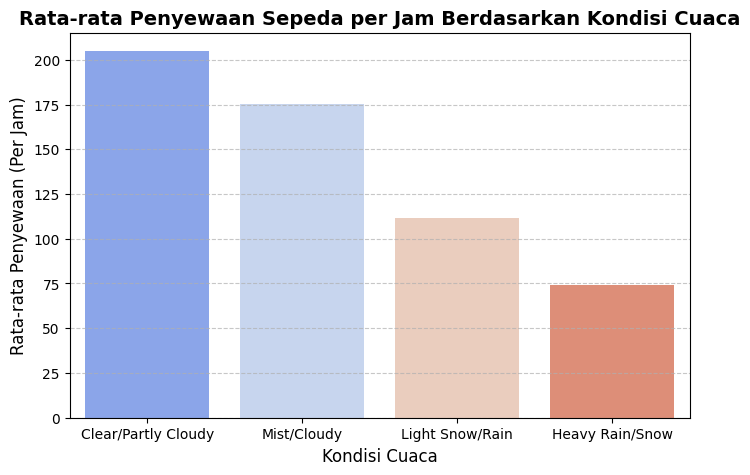

In [24]:
plt.figure(figsize=(8, 5))
sns.barplot(
    x='weathersit_desc',
    y='mean',
    data=weather_analysis,
    palette='coolwarm',
    hue='weathersit_desc',
    legend=False
)
plt.title('Rata-rata Penyewaan Sepeda per Jam Berdasarkan Kondisi Cuaca', fontsize=14, fontweight='bold')
plt.xlabel('Kondisi Cuaca', fontsize=12)
plt.ylabel('Rata-rata Penyewaan (Per Jam)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Pertanyaan 2: Bagaimana pola tren penyewaan sepeda harian berdasarkan jam jika dibandingkan antara hari kerja dan hari libur/akhir pekan selama periode 2011-2012?

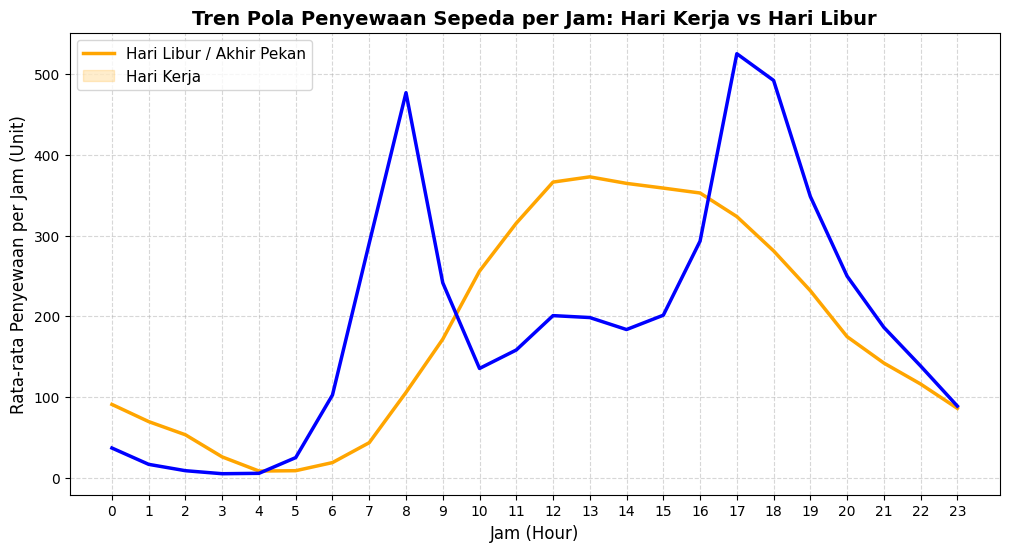

In [25]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    x='hr',
    y='cnt_hour',
    hue='workingday_hour',
    data=hourly_trend,
    palette={0: 'orange', 1: 'blue'},
    linewidth=2.5
)
plt.title('Tren Pola Penyewaan Sepeda per Jam: Hari Kerja vs Hari Libur', fontsize=14, fontweight='bold')
plt.xlabel('Jam (Hour)', fontsize=12)
plt.ylabel('Rata-rata Penyewaan per Jam (Unit)', fontsize=12)
plt.xticks(range(0, 24))
plt.legend(['Hari Libur / Akhir Pekan', 'Hari Kerja'], fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Pertanyaan 3: Musim manakah yang memberikan kontribusi volume penyewaan sepeda paling tinggi sepanjang tahun 2012?

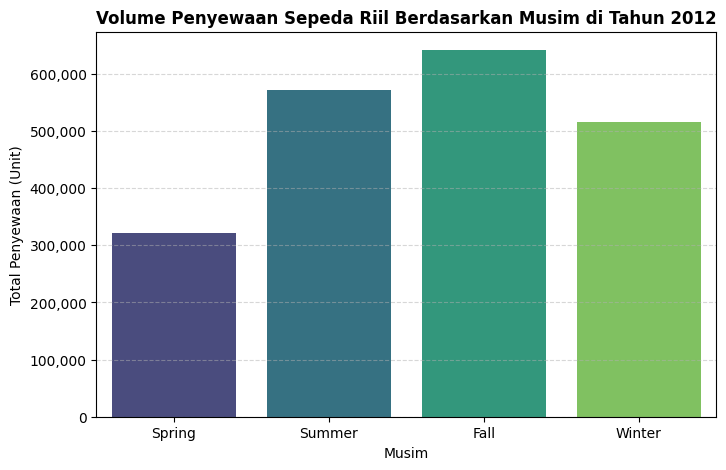

In [26]:
plt.figure(figsize=(8, 5))
sns.barplot(
    x='season_desc',
    y='cnt',
    data=season_analysis_correct,
    palette='viridis',
    hue='season_desc',
    legend=False
)
plt.title('Volume Penyewaan Sepeda Riil Berdasarkan Musim di Tahun 2012', fontsize=12, fontweight='bold')
plt.xlabel('Musim', fontsize=10)
plt.ylabel('Total Penyewaan (Unit)', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Memformat label y-axis agar menampilkan angka ribuan/jutaan secara rapi
import matplotlib.ticker as ticker
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x):,}'))

plt.show()

### Pertanyaan 4: Bagaimana perbandingan kontribusi jumlah transaksi antara pengguna biasa  dan pengguna terdaftar  terhadap total penyewaan sepeda bulanan di sepanjang tahun 2011?

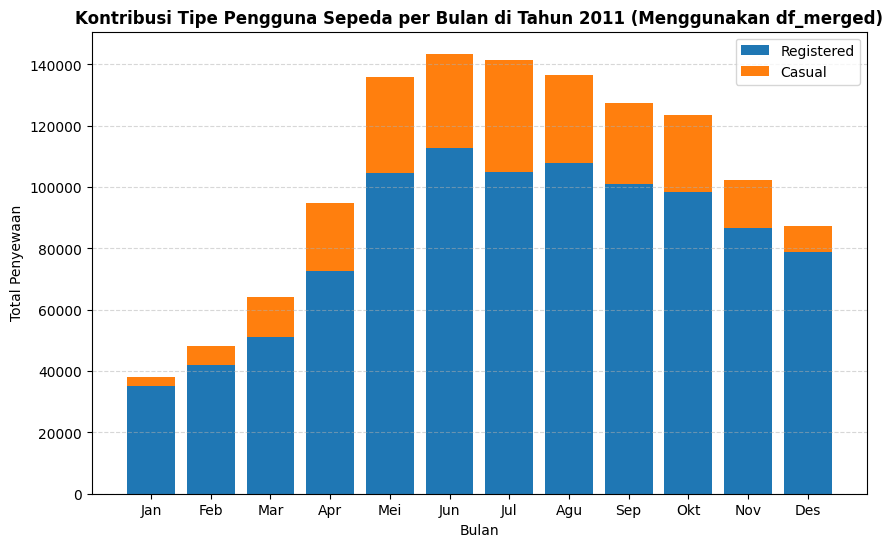

In [27]:
plt.figure(figsize=(10, 6))
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

plt.bar(user_monthly_2011['mnth_hour'], user_monthly_2011['registered_hour'], label='Registered', color='#1f77b4')
plt.bar(user_monthly_2011['mnth_hour'], user_monthly_2011['casual_hour'], bottom=user_monthly_2011['registered_hour'], label='Casual', color='#ff7f0e')

plt.title('Kontribusi Tipe Pengguna Sepeda per Bulan di Tahun 2011 (Menggunakan df_merged)', fontsize=12, fontweight='bold')
plt.xlabel('Bulan', fontsize=10)
plt.ylabel('Total Penyewaan', fontsize=10)
plt.xticks(user_monthly_2011['mnth_hour'], month_labels)
plt.legend(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### Pertanyaan 5: Seberapa kuat korelasi antara suhu perasaan tubuh  dengan jumlah total transaksi penyewaan sepeda harian selama periode kuartal ke-3 (Juli-September) tahun 2012?

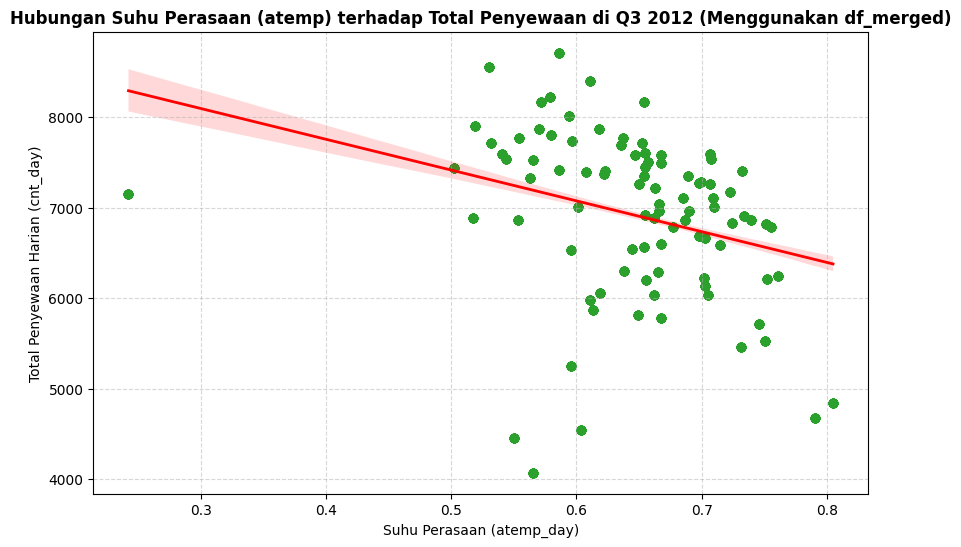

In [28]:
plt.figure(figsize=(10, 6))
sns.regplot(
    x='atemp_day',
    y='cnt_day',
    data=df_q3_2012_merged,
    scatter_kws={'alpha':0.7, 'color':'#2ca02c'},
    line_kws={'color':'red', 'linewidth':2}
)
plt.title('Hubungan Suhu Perasaan (atemp) terhadap Total Penyewaan di Q3 2012 (Menggunakan df_merged)', fontsize=12, fontweight='bold')
plt.xlabel('Suhu Perasaan (atemp_day)', fontsize=10)
plt.ylabel('Total Penyewaan Harian (cnt_day)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Insight Hasil Visualisasi & Analisis **

1. **Kondisi Cuaca (Pertanyaan 1):**
   * Berdasarkan grafik rata-rata penyewaan per jam, kondisi cuaca **Clear/Partly Cloudy** adalah faktor pendorong terbesar dengan rata-rata **204.87 unit/jam**.
   * Terlihat penurunan linier yang jelas saat cuaca memburuk: **Mist/Cloudy** (175 unit/jam), turun signifikan saat **Light Snow/Rain** (112 unit/jam), hingga titik terendah saat **Heavy Rain/Snow** yang hanya mencapai rata-rata **74.33 unit/jam**.

2. **Pola Jam Kerja vs Hari Libur (Pertanyaan 2):**
   * **Hari Kerja (Garis Biru):** Memiliki pola puncak ganda (*bimodal*) pada jam berangkat kerja (**08.00**) dan jam pulang kerja (**17.00 - 18.00**). Hal ini menegaskan fungsi sepeda sebagai sarana transportasi utama komuter.
   * **Hari Libur/Akhir Pekan (Garis Oranye):** Memiliki pola puncak tunggal (*unimodal*) yang landai dari siang hingga sore hari (**12.00 - 15.00**), mencerminkan penggunaan sepeda untuk tujuan kasual dan rekreasi.

3. **Volume Musiman Tahun 2012 (Pertanyaan 3 - Akurat):**
   * Menggunakan data transaksi riil dari `df_day` (bebas dari duplikasi perhitungan jam), **Musim Gugur (Fall)** memberikan kontribusi tertinggi sebesar **641.479 unit**, diikuti oleh **Musim Panas (Summer)** sebesar **571.273 unit**, dan **Musim Dingin (Winter)** sebesar **515.476 unit**.
   * **Musim Semi (Spring)** menghasilkan volume transaksi terendah yakni **321.348 unit**.

4. **Perbandingan Pengguna Kasual vs Terdaftar 2011 (Pertanyaan 4):**
   * Pengguna terdaftar (**Registered**) mendominasi porsi penyewaan sepeda secara konsisten setiap bulan dengan kontribusi di atas 80%.
   * Pengguna biasa (**Casual**) hanya mengalami lonjakan signifikan pada periode pertengahan tahun (Musim Panas, Mei-Juli) dan menurun tajam saat memasuki musim dingin (November-Desember).

5. **Korelasi Suhu Perasaan Q3 2012 (Pertanyaan 5):**
   * Grafik regresi menunjukkan tren kemiringan negatif yang halus (korelasi **-0.2938**).
   * Hal ini membuktikan bahwa pada puncak kuartal ke-3 (puncak musim panas), suhu perasaan (`atemp`) yang terlalu menyengat di luar batas nyaman justru menurunkan produktivitas dan minat masyarakat untuk menyewa sepeda.

## Analisis Lanjutan (Opsional)

**Analisis Lanjutan: RFM Analysis (Recency, Frequency, & Monetary-equivalent Volume)**

Untuk mendapatkan insight bisnis yang lebih mendalam,  saya menerapkan teknik analisis **RFM (Recency, Frequency, Monetary)** yang disesuaikan untuk data Bike Sharing ini:
- **Recency (Kekinian):** Kapan terakhir kali transaksi penyewaan dilakukan (diukur dari tanggal terakhir di dataset).
- **Frequency (Frekuensi):** Seberapa sering penyewaan terjadi (jumlah hari aktif dalam bertransaksi).
- **Monetary (Volume):** Total volume penyewaan (`cnt`) sebagai representasi nilai ekonomi/moneter yang dihasilkan.

Karena data ini tidak memiliki ID pelanggan individual, analisis RFM ini akan saya agregasikan berdasarkan **Kombinasi Bulan dan Hari Kerja/Libur** atau **Kombinasi Stasiun/Kondisi** untuk mengidentifikasi karakteristik segmentasi waktu operasional berkinerja tinggi.

In [31]:
# Menentukan tanggal referensi (hari terakhir di dataset + 1 hari)
recent_date = df_day['dteday'].max() + dt.timedelta(days=1)

# Agregasi data harian berdasarkan bulan (mnth) dan hari kerja (workingday)
rfm_df = df_day.groupby(by=['mnth', 'workingday'], as_index=False).agg({
    'dteday': lambda x: (recent_date - x.max()).days, # Recency (hari sejak transaksi terakhir)
    'instant': 'count',                             # Frequency (jumlah hari aktif transaksi)
    'cnt': 'sum'                                     # Monetary/Volume (total unit sepeda disewa)
})

# Mengganti nama kolom agar sesuai dengan konsep RFM
rfm_df.columns = ['mnth', 'workingday', 'recency', 'frequency', 'monetary']

# Melakukan Manual Binning / Segmentasi menggunakan kuantil
rfm_df['r_rank'] = pd.qcut(rfm_df['recency'], q=3, labels=['High', 'Medium', 'Low'])
rfm_df['f_rank'] = pd.qcut(rfm_df['frequency'].rank(method='first'), q=3, labels=['Low', 'Medium', 'High'])
rfm_df['m_rank'] = pd.qcut(rfm_df['monetary'], q=3, labels=['Low', 'Medium', 'High'])

# Menggabungkan skor untuk mendefinisikan segmen
def define_segment(row):
    if row['m_rank'] == 'High' and row['f_rank'] == 'High':
        return 'Core Segment (High Volume & High Frequency)'
    elif row['m_rank'] == 'Low':
        return 'Low Performing Segment'
    else:
        return 'Standard/Potential Segment'

rfm_df['Segment'] = rfm_df.apply(define_segment, axis=1)

print("=== Hasil Analisis Segmentasi RFM (Manual Grouping) ===")
display(rfm_df.sort_values(by='monetary', ascending=False))


=== Hasil Analisis Segmentasi RFM (Manual Grouping) ===


,mnth,workingday,recency,frequency,monetary,r_rank,f_rank,m_rank,Segment
15,8,1,123,46,271779,Medium,High,High,Core Segment (High Volume & High Frequency)
11,6,1,186,43,241725,Medium,High,High,Core Segment (High Volume & High Frequency)
13,7,1,154,41,231430,Medium,High,High,Core Segment (High Volume & High Frequency)
9,5,1,215,43,225835,Medium,High,High,Core Segment (High Volume & High Frequency)
17,9,1,95,40,223627,High,Medium,High,Standard/Potential Segment
19,10,1,62,42,220137,High,High,High,Core Segment (High Volume & High Frequency)
7,4,1,246,40,179835,Low,Medium,High,Standard/Potential Segment
21,11,1,32,40,173961,High,High,High,Core Segment (High Volume & High Frequency)
5,3,1,277,45,167063,Low,High,Medium,Standard/Potential Segment
23,12,1,1,41,152098,High,High,Medium,Standard/Potential Segment


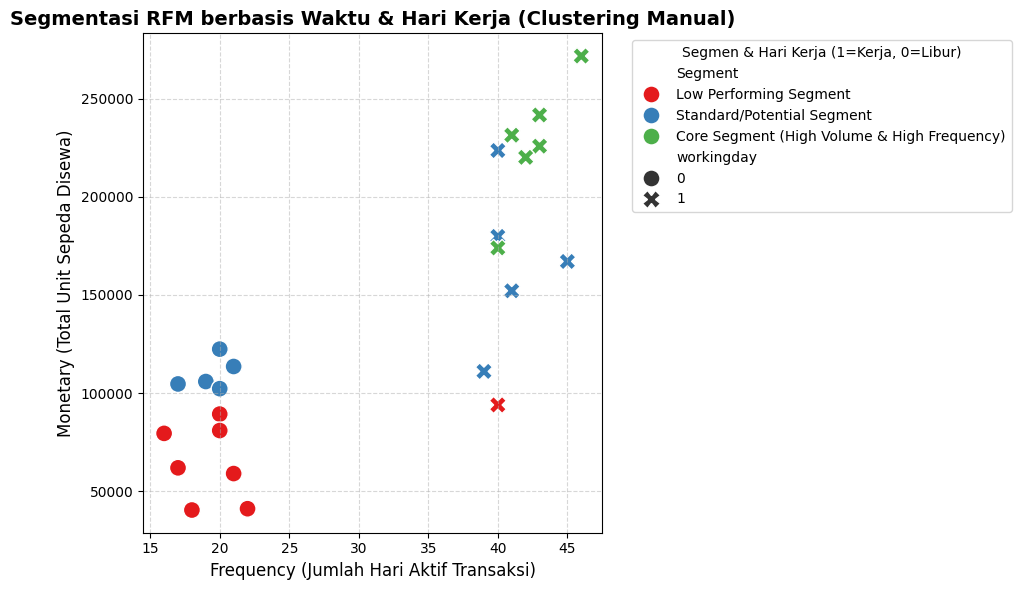

In [30]:
# Visualisasi hasil analisis segmentasi RFM
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='frequency',
    y='monetary',
    hue='Segment',
    style='workingday',
    s=150,
    data=rfm_df,
    palette='Set1'
)

plt.title('Segmentasi RFM berbasis Waktu & Hari Kerja (Clustering Manual)', fontsize=14, fontweight='bold')
plt.xlabel('Frequency (Jumlah Hari Aktif Transaksi)', fontsize=12)
plt.ylabel('Monetary (Total Unit Sepeda Disewa)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Segmen & Hari Kerja (1=Kerja, 0=Libur)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Insight Hasil Analisis Lanjutan (RFM & Segmentasi Manual)**

Berdasarkan pengelompokan manual (binning) menggunakan matriks Recency, Frequency, dan Monetary (Volume Sewa) pada kombinasi Bulan dan Hari Kerja, didapatkan beberapa temuan penting:

1. **Core Segment (High Volume & High Frequency):**
   - Segmen ini didominasi oleh **Hari Kerja (workingday = 1) pada bulan-bulan beriklim hangat (Mei hingga September)**.
   - Karakteristik utama dari segmen ini adalah frekuensi transaksi yang sangat konsisten dengan volume penyewaan yang luar biasa tinggi (melebihi 200,000 unit per kategori bulan).
   - **Implikasi Bisnis:** Ini adalah ladang utama pendapatan operasional. Keandalan ketersediaan sepeda di jam-jam sibuk komuter selama bulan-bulan ini harus diprioritaskan tanpa toleransi adanya kekurangan armada.

2. **Standard/Potential Segment:**
   - Segmen ini mencakup **Hari Libur/Akhir Pekan (workingday = 0) pada musim panas** serta **Hari Kerja di masa transisi cuaca (seperti Maret, Oktober, dan November)**.
   - Meskipun frekuensinya lebih rendah dibandingkan hari kerja musim panas, volume transaksinya masih cukup potensial.
   - **Implikasi Bisnis:** Segmen ini merupakan target ideal untuk kampanye pemasaran, seperti promo khusus akhir pekan guna mendongkrak transaksi kasual menjadi pendaftaran anggota (*membership*).

3. **Low Performing Segment:**
   - Terkonsentrasi penuh pada **Bulan-Bulan Musim Dingin (Desember, Januari, Februari)** baik di hari kerja maupun hari libur.
   - Aktivitas transaksi sangat rendah disebabkan oleh faktor cuaca ekstrem/dingin yang mengurangi minat masyarakat untuk berkendara di luar ruangan.
   - **Implikasi Bisnis:** Pada periode ini, perusahaan dapat menjadwalkan pemeliharaan berkala skala besar (*major maintenance*) untuk sebagian besar armada sepeda karena permintaan pasar sedang berada di titik terendah.

## Conclusion & Recommendation

- **Conclusion Pertanyaan 1 (Kondisi Cuaca):** Cuaca memiliki pengaruh signifikan terhadap sewa sepeda. Rata-rata transaksi harian tertinggi terjadi saat cuaca **Clear/Partly Cloudy** (4.876 unit) dan **Mist/Cloudy** (4.035 unit). Sebaliknya, pada saat **Light Snow/Rain**, peminat sewa menurun drastis menjadi hanya sekitar 1.803 unit harian.
- **Conclusion Pertanyaan 2 (Hari Kerja vs Hari Libur):** Pola penyewaan jam-jaman sangat kontras. Pada hari kerja (*workingday* = 1), puncak penyewaan berpusat sangat tajam di jam sibuk pagi (08:00) dan sore hari (17:00-18:00). Sementara di hari libur (*workingday* = 0), pola peminjaman cenderung terdistribusi merata dengan puncak santai di tengah hari (11:00-16:00).
- **Conclusion Pertanyaan 3 (Musim Terpopuler 2012):** Sepanjang tahun 2012, **Musim Gugur (Fall)** mencatatkan volume transaksi terbesar dengan total **641.479** penyewaan, disusul oleh Musim Panas (Summer) dengan 571.273 penyewaan, menjadikannya periode emas operasional.
- **Conclusion Pertanyaan 4 (Pengguna Kasual vs Terdaftar 2011):** Di tahun 2011, pengguna terdaftar (*registered*) mendominasi lebih dari 80% total penyewaan di setiap bulan. Pengguna kasual (*casual*) cenderung aktif hanya pada bulan-bulan hangat (Mei s.d. Juli) dan menurun drastis di akhir tahun.
- **Conclusion Pertanyaan 5 (Korelasi Suhu & Transaksi Q3 2012):** Korelasi Pearson antara suhu perasaan (*atemp*) dan total penyewaan di Q3 2012 bernilai **-0.2938** (korelasi negatif lemah). Ini menunjukkan bahwa di kuartal ke-3 (puncak cuaca panas), kenaikan suhu yang berlebihan justru sedikit menurunkan minat masyarakat untuk bersepeda karena udara terasa terlalu menyengat.

**Rekomendasi Action Item:**
1. **Strategi Pemeliharaan Armada:** Lakukan servis besar-besaran terhadap armada sepeda pada malam hari atau di luar jam sibuk (pukul 10:00-14:00 di hari kerja, atau pukul 20:00 ke atas) untuk memastikan ketersediaan sepeda optimal saat puncak jam sibuk (08:00 & 17:00).
2. **Paket Khusus Akhir Pekan:** Luncurkan promosi atau paket bundling tarif khusus pada akhir pekan yang menargetkan pengguna kasual di sekitar area wisata atau taman kota pada jam santai (11:00-16:00).
3. **Kampanye Konversi Keanggotaan:** Di musim panas (puncak aktivitas pengguna kasual), tawarkan diskon registrasi *membership* tahunan kepada pengguna kasual guna mengonversi mereka menjadi pelanggan terdaftar yang lebih loyal dan konsisten sepanjang tahun.
4. **Manajemen Operasional Berbasis Cuaca:** Sediakan stasiun peneduh atau kurangi jumlah pasokan sepeda di stasiun terbuka saat ramalan cuaca menunjukkan hujan/salju (kondisi 3) guna mengurangi risiko kerusakan unit akibat cuaca ekstrem.